# Liu et al. (2024): minimal kinetic model of direct air capture

Reproduction of Figures 1-7 of H. Liu, H. Lin, S. Dai and D.-e. Jiang, *Ind. Eng. Chem. Res.* **63** (2024) 5871-5879, DOI `10.1021/acs.iecr.3c04535`.

Every solid curve in this notebook is read from a RUPTURA simulation under `simulations/`. Nothing is computed here and nothing is loaded from a stored result table. `generate.py` writes the input decks, `run.py` executes them, and the cells below read the resulting `component_*.data` files.

Every dashed curve with open markers is digitized from the published panels and lives in `reference_digitized/`. Those are graphical reconstructions of the printed figures, not the authors' numerical data.

Unit conversions between the article's quantities and the RUPTURA inputs are derived in `conversions.md`.

In [1]:
from pathlib import Path
import csv
import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd()
if ROOT.name != "liu":
    ROOT = ROOT / "liu"
SIMULATION_DIR = ROOT / "simulations"
REFERENCE_DIR = ROOT / "reference_digitized"
FIGURE_DIR = ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

GAS_CONSTANT = 8.31446261815324  # J mol-1 K-1

INDEX = json.loads((SIMULATION_DIR / "index.json").read_text())

## Reading RUPTURA output

`component_<i>_<name>.data` holds one block of grid points per written time step. The columns used below are time (2, in minutes), column position (3), concentration (4), partial pressure (11), physisorption loading (7) and equilibrium physisorption loading (12).

In [2]:
def case(**filters):
    """The single ``simulations/index.json`` entry matching every keyword."""

    def matches(entry):
        for key, expected in filters.items():
            if key not in entry:
                return False
            if isinstance(expected, float):
                if not np.isclose(entry[key], expected):
                    return False
            elif entry[key] != expected:
                return False
        return True

    selected = [entry for entry in INDEX if matches(entry)]
    if len(selected) != 1:
        raise LookupError(f"{len(selected)} index entries match {filters}")
    return selected[0]


def read_component(entry, component):
    """Every written grid block of one component, as a dict of 2-D arrays [time, position].

    The returned arrays are indexed ``[time_index, grid_index]`` so that an outlet
    history is ``array[:, -1]`` and a bed average is ``array.mean(axis=1)``.
    """

    directory = SIMULATION_DIR / entry["directory"]
    matches = sorted(directory.glob(f"component_*_{component}.data"))
    if not matches:
        raise FileNotFoundError(f"no {component} output in {directory}; run run.py first")
    if "Final time:" not in (directory / "run.log").read_text():
        raise RuntimeError(f"{entry['directory']} has not finished; wait for run.py")
    raw = np.loadtxt(matches[0])

    positions = np.unique(raw[:, 2])
    blocks = raw.reshape(-1, len(positions), raw.shape[1])
    return {
        "time_s": blocks[:, 0, 1] * 60.0,
        "position_m": positions,
        "concentration_mol_m3": blocks[:, :, 3],
        "loading_mol_kg": blocks[:, :, 6],
        "partial_pressure_pa": blocks[:, :, 10],
        "equilibrium_loading_mol_kg": blocks[:, :, 11],
        "normalized_pressure": blocks[:, :, 12],
    }


def read_isotherm(entry, component):
    """Pressure and loading of a ``MixturePrediction`` run, in Pa and mol/kg."""

    directory = SIMULATION_DIR / entry["directory"]
    matches = sorted(directory.glob(f"component_*_{component}.data"))
    if not matches:
        raise FileNotFoundError(f"no {component} output in {directory}; run run.py first")
    raw = np.loadtxt(matches[0])
    return raw[:, 0], raw[:, 1]


def sampled_isotherm(entry, component, bins=220):
    """The isotherm RUPTURA itself evaluated during a breakthrough run.

    Every grid point of every written block reports its local partial pressure
    beside the equilibrium loading at that pressure, so a developing front traces
    out the isotherm.  The pairs are binned on a log pressure grid because the
    front revisits the same pressures many times.  This is how the Figure 5a
    water isotherm is obtained: RUPTURA's ``MixturePrediction`` writer always
    evaluates a reduced grand potential, which a GAB site does not define.
    """

    data = read_component(entry, component)
    pressure = data["partial_pressure_pa"].ravel()
    loading = data["equilibrium_loading_mol_kg"].ravel()
    finite = (pressure > 0.0) & np.isfinite(loading)
    pressure, loading = pressure[finite], loading[finite]

    edges = np.geomspace(pressure.min(), pressure.max(), bins + 1)
    index = np.clip(np.digitize(pressure, edges) - 1, 0, bins - 1)
    counts = np.bincount(index, minlength=bins)
    occupied = counts > 0
    mean_pressure = np.bincount(index, weights=pressure, minlength=bins)[occupied] / counts[occupied]
    mean_loading = np.bincount(index, weights=loading, minlength=bins)[occupied] / counts[occupied]
    return mean_pressure, mean_loading


def worst_backward_step(series):
    """The largest decrease in a curve that physics says must rise, or 0.0.

    A single-adsorbate breakthrough curve at constant feed is monotonic, so any
    decrease is integration error.  The Figure 4 runs need a looser CVODE
    tolerance than the rest to be tractable at all, so their curves are checked
    and the result is printed with the figure instead of being left to the eye.
    """

    differences = np.diff(np.asarray(series))
    return float(min(differences.min(), 0.0))


def reference(number, x, y, **filters):
    """Two digitized columns of ``reference_digitized/figure_<number>.csv``."""

    with (REFERENCE_DIR / f"figure_{number}.csv").open(newline="") as handle:
        rows = list(csv.DictReader(handle))

    def matches(row):
        for key, expected in filters.items():
            if isinstance(expected, str):
                if row[key] != expected:
                    return False
            elif not np.isclose(float(row[key]), expected, rtol=1e-6, atol=1e-12):
                return False
        return True

    selected = [row for row in rows if matches(row)]
    if not selected:
        raise LookupError(f"no digitized figure {number} data matches {filters}")
    return (
        np.array([float(row[x]) for row in selected]),
        np.array([float(row[y]) for row in selected]),
    )

## Figure style

Every figure is 8 by 6 inches with 12 pt ticks, 14 pt axis labels and legends, and 16 pt titles. Solid lines are RUPTURA; dashed lines with open markers are the digitized Liu reference. Each panel carries two legends: one naming the conditions by colour, one naming the two sources by line style.

In [3]:
plt.style.use("default")
plt.rcParams.update(
    {
        "figure.figsize": (8, 6),
        "savefig.dpi": 300,
        "font.size": 12,
        "axes.labelsize": 14,
        "axes.titlesize": 16,
        "axes.labelpad": 6.0,
        "axes.grid": False,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 14,
        "lines.linewidth": 2.0,
    }
)

RUPTURA_STYLE = dict(linestyle="-")
REFERENCE_STYLE = dict(linestyle="--", linewidth=1.5, markersize=6, markerfacecolor="none", markeredgewidth=1.2)
REFERENCE_MARKERS = ("o", "s", "D", "^", "v", "<", ">", "p")


def tick_label(value, _position=None):
    """Plain decimal, or LaTeX scientific once six or more digits are needed."""

    if value == 0:
        return "0"
    plain = np.format_float_positional(float(f"{value:.10g}"), trim="-")
    if sum(character.isdigit() for character in plain) < 6:
        return plain
    exponent = int(np.floor(np.log10(abs(value))))
    mantissa = value / 10.0**exponent
    if np.isclose(mantissa, 1.0):
        return rf"$10^{{{exponent}}}$"
    return rf"${mantissa:g} \times 10^{{{exponent}}}$"


TICKS = FuncFormatter(tick_label)


def source_legend(axis, condition_handles, *, condition_loc="best", source_loc="lower right", title=None):
    """Two legends: conditions by colour, and the RUPTURA/Liu line-style key."""

    source_handles = [
        Line2D([], [], color="0.25", label="RUPTURA", **RUPTURA_STYLE),
        Line2D([], [], color="0.25", marker="o", label="Liu et al.", **REFERENCE_STYLE),
    ]
    conditions = axis.legend(handles=condition_handles, loc=condition_loc, title=title)
    axis.add_artist(conditions)
    axis.legend(handles=source_handles, loc=source_loc)

## Figure 1 - flue-gas benchmark

Panel (a) is the Toth isotherm of the flue-gas sorbent at 298 and 318 K, evaluated by RUPTURA through equations 4-6. Panel (b) is the dry 10132.5 Pa CO$_2$ breakthrough. The reference column length and bulk density are calibrated to the printed time scale, because the article does not repeat the apparatus dimensions of its reference 21.

### Figure 1a - CO$_2$ isotherms at 298 and 318 K

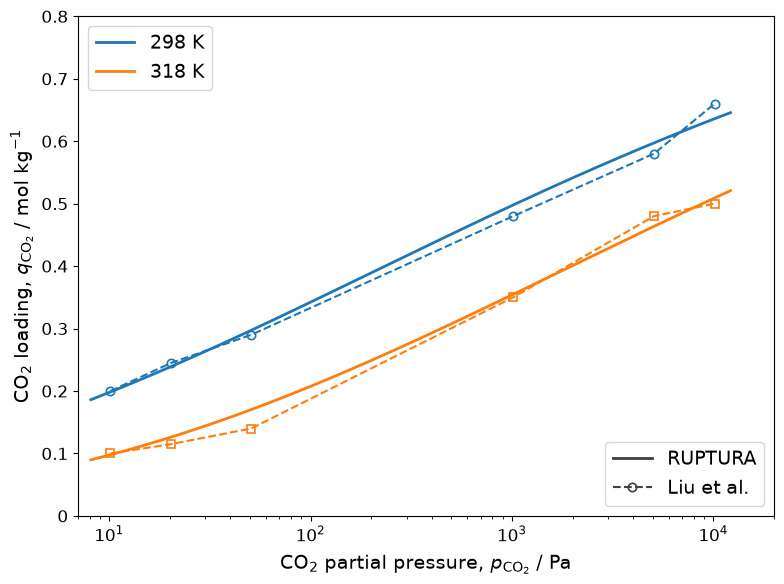

In [4]:
fig, ax = plt.subplots()
handles = []
for index, temperature in enumerate((298.15, 318.15)):
    entry = case(figure=1, panel="a", temperature_K=temperature)
    pressure, loading = read_isotherm(entry, "CO2")
    color = f"C{index}"
    ax.semilogx(pressure, loading, color=color, label=entry["legend"], **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    marker_pressure, marker_loading = reference(
        1, "pressure_pa", "loading_mol_kg", dataset="isotherm", temperature_K=temperature
    )
    ax.semilogx(
        marker_pressure,
        marker_loading,
        color=color,
        marker=REFERENCE_MARKERS[index],
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"CO$_2$ partial pressure, $p_\mathrm{CO_2}$ / Pa")
ax.set_ylabel(r"CO$_2$ loading, $q_\mathrm{CO_2}$ / mol kg$^{-1}$")
ax.set_xlim(7.0, 20_000.0)
ax.set_ylim(0.0, 0.8)
ax.yaxis.set_major_formatter(TICKS)
source_legend(ax, handles, condition_loc="upper left", source_loc="lower right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_1a.pdf", dpi=300)

### Figure 1b - dry 10132.5 Pa CO$_2$ breakthrough at 298 K

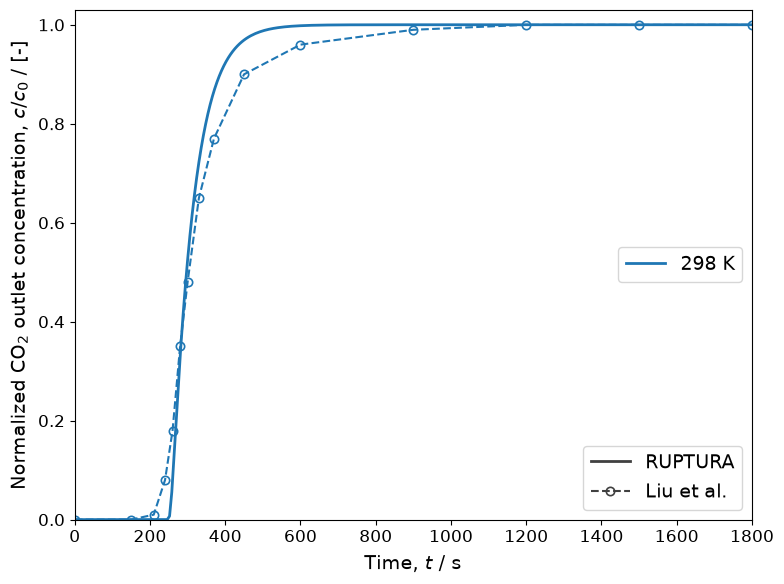

In [5]:
fig, ax = plt.subplots()
entry = case(figure=1, panel="b")
data = read_component(entry, "CO2")
ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color="C0", **RUPTURA_STYLE)

reference_time, reference_outlet = reference(
    1, "time_s", "outlet_fraction", dataset="breakthrough", temperature_K=298.15
)
ax.plot(reference_time, reference_outlet, color="C0", marker="o", **REFERENCE_STYLE)

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(0.0, 1800.0)
ax.set_ylim(0.0, 1.03)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax,
    [Line2D([], [], color="C0", label=entry["legend"], **RUPTURA_STYLE)],
    condition_loc="center right",
    source_loc="lower right",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_1b.pdf", dpi=300)

## Figure 2 - kinetic and bed-operation sweeps

Breakthrough of the Table 2 baseline at 0.016 mol m$^{-3}$ CO$_2$ and 298 K, sweeping the linear-driving-force rate constant, the superficial velocity and the bed length one at a time.

### Figure 2a - uptake-rate constant

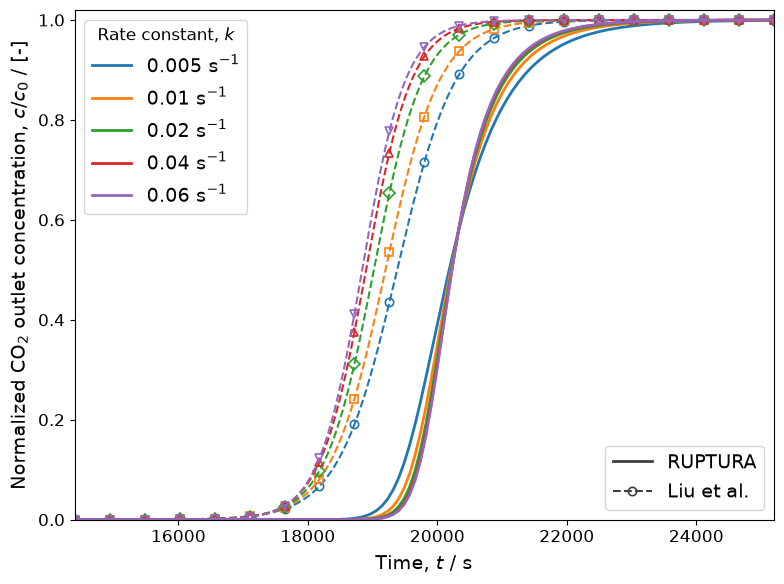

In [6]:
fig, ax = plt.subplots()
handles = []
for index, value in enumerate([0.005, 0.01, 0.02, 0.04, 0.06]):
    entry = case(figure=2, sweep="rate_constant", sweep_value=value)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    reference_time, reference_outlet = reference(
        2,
        "time_s",
        "outlet_fraction",
        sweep_parameter=entry["reference_sweep_parameter"],
        sweep_value=entry["reference_sweep_value"],
    )
    ax.plot(
        reference_time,
        reference_outlet,
        color=color,
        marker=REFERENCE_MARKERS[index],
        markevery=max(1, len(reference_time) // 20),
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(14_400.0, 25_200.0)
ax.set_ylim(0.0, 1.02)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax, handles, condition_loc="upper left", source_loc="lower right", title=r"Rate constant, $k$"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_2a.pdf", dpi=300)

### Figure 2b - superficial velocity

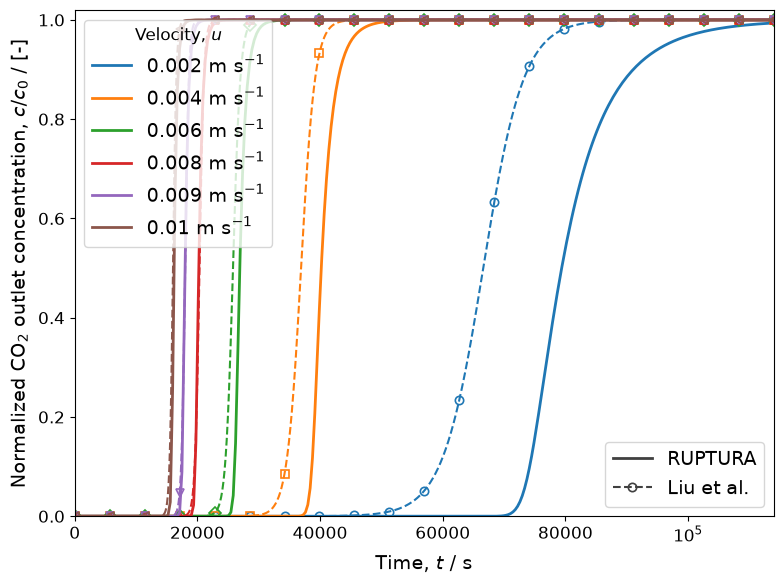

In [7]:
fig, ax = plt.subplots()
handles = []
for index, value in enumerate([0.002, 0.004, 0.006, 0.008, 0.009, 0.010]):
    entry = case(figure=2, sweep="velocity", sweep_value=value)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    reference_time, reference_outlet = reference(
        2,
        "time_s",
        "outlet_fraction",
        sweep_parameter=entry["reference_sweep_parameter"],
        sweep_value=entry["reference_sweep_value"],
    )
    ax.plot(
        reference_time,
        reference_outlet,
        color=color,
        marker=REFERENCE_MARKERS[index],
        markevery=max(1, len(reference_time) // 20),
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(0.0, 114_000.0)
ax.set_ylim(0.0, 1.02)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax, handles, condition_loc="upper left", source_loc="lower right", title=r"Velocity, $u$"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_2b.pdf", dpi=300)

### Figure 2c - bed length

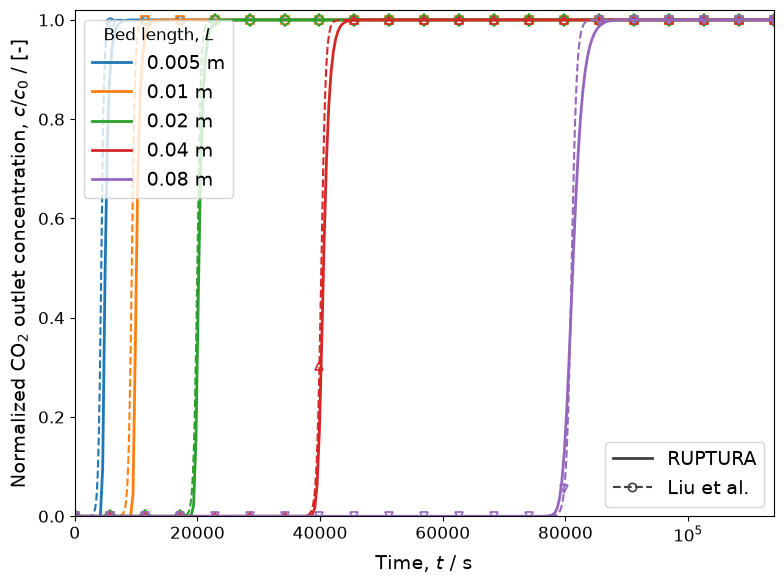

In [8]:
fig, ax = plt.subplots()
handles = []
for index, value in enumerate([0.005, 0.010, 0.020, 0.040, 0.080]):
    entry = case(figure=2, sweep="length", sweep_value=value)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    reference_time, reference_outlet = reference(
        2,
        "time_s",
        "outlet_fraction",
        sweep_parameter=entry["reference_sweep_parameter"],
        sweep_value=entry["reference_sweep_value"],
    )
    ax.plot(
        reference_time,
        reference_outlet,
        color=color,
        marker=REFERENCE_MARKERS[index],
        markevery=max(1, len(reference_time) // 20),
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(0.0, 114_000.0)
ax.set_ylim(0.0, 1.02)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax, handles, condition_loc="upper left", source_loc="lower right", title=r"Bed length, $L$"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_2c.pdf", dpi=300)

## Figure 3 - Toth parameter sweeps

The same Table 2 baseline, sweeping the three Toth parameters: saturation loading $n_s$, affinity $b$ and exponent $t_T$.

### Figure 3a - saturation loading

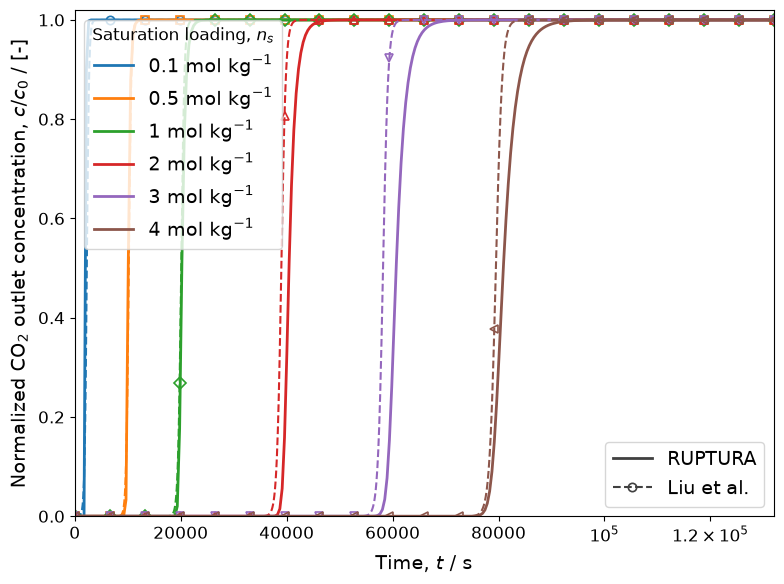

In [9]:
fig, ax = plt.subplots()
handles = []
for index, value in enumerate([0.1, 0.5, 1.0, 2.0, 3.0, 4.0]):
    entry = case(figure=3, sweep="saturation_loading", sweep_value=value)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    reference_time, reference_outlet = reference(
        3,
        "time_s",
        "outlet_fraction",
        sweep_parameter=entry["reference_sweep_parameter"],
        sweep_value=entry["reference_sweep_value"],
    )
    ax.plot(
        reference_time,
        reference_outlet,
        color=color,
        marker=REFERENCE_MARKERS[index],
        markevery=max(1, len(reference_time) // 20),
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(0.0, 132_000.0)
ax.set_ylim(0.0, 1.02)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax,
    handles,
    condition_loc="upper left",
    source_loc="lower right",
    title=r"Saturation loading, $n_s$",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_3a.pdf", dpi=300)

### Figure 3b - affinity

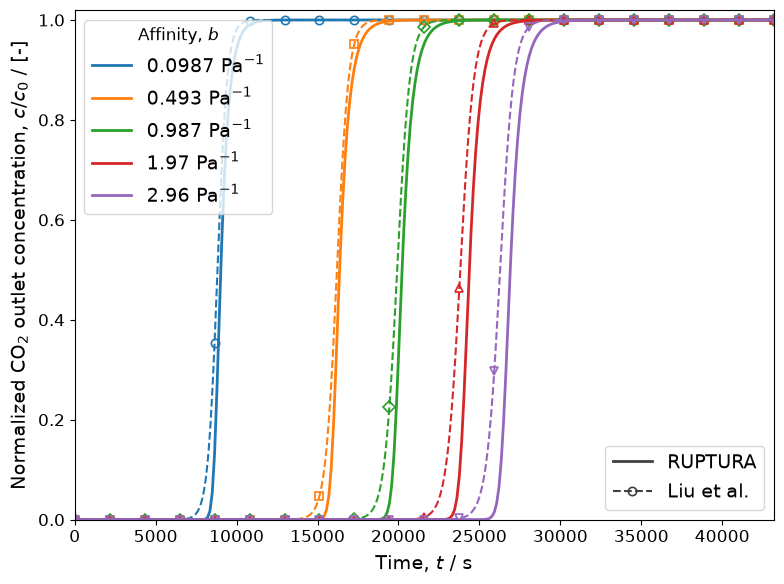

In [10]:
fig, ax = plt.subplots()
handles = []
for index, value in enumerate([1.0e4, 5.0e4, 1.0e5, 2.0e5, 3.0e5]):
    entry = case(figure=3, sweep="affinity", sweep_value=value / 101_325.0)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    reference_time, reference_outlet = reference(
        3,
        "time_s",
        "outlet_fraction",
        sweep_parameter=entry["reference_sweep_parameter"],
        sweep_value=entry["reference_sweep_value"],
    )
    ax.plot(
        reference_time,
        reference_outlet,
        color=color,
        marker=REFERENCE_MARKERS[index],
        markevery=max(1, len(reference_time) // 20),
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(0.0, 43_200.0)
ax.set_ylim(0.0, 1.02)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax, handles, condition_loc="upper left", source_loc="lower right", title=r"Affinity, $b$"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_3b.pdf", dpi=300)

### Figure 3c - Toth exponent

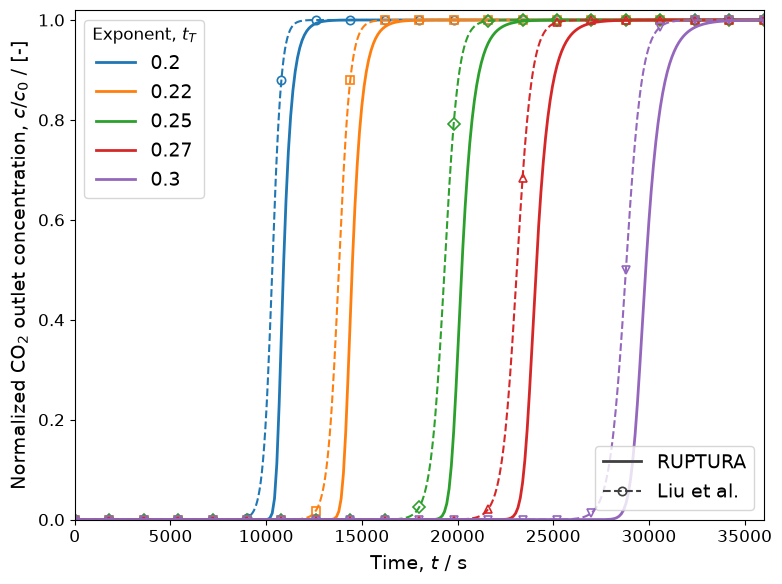

In [11]:
fig, ax = plt.subplots()
handles = []
for index, value in enumerate([0.20, 0.22, 0.25, 0.27, 0.30]):
    entry = case(figure=3, sweep="exponent", sweep_value=value)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    reference_time, reference_outlet = reference(
        3,
        "time_s",
        "outlet_fraction",
        sweep_parameter=entry["reference_sweep_parameter"],
        sweep_value=entry["reference_sweep_value"],
    )
    ax.plot(
        reference_time,
        reference_outlet,
        color=color,
        marker=REFERENCE_MARKERS[index],
        markevery=max(1, len(reference_time) // 20),
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(0.0, 36_000.0)
ax.set_ylim(0.0, 1.02)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax, handles, condition_loc="upper left", source_loc="lower right", title=r"Exponent, $t_T$"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_3c.pdf", dpi=300)

## Figure 4 - humidity effects

Coupled H$_2$O/CO$_2$ breakthrough with the GAB water isotherm of equation 7 and the humid modified Toth law of equation 8. RUPTURA's `GAB-modified-Toth` site makes $n_s$ and $b$ follow the GAB water loading at the local water partial pressure of the H$_2$O component (`"Water": true`), its equilibrium loading rather than the transported one. Water saturates the bed within a few thousand seconds while the CO$_2$ front needs tens of thousands, so freezing the law at the feed humidity, as these runs did until 2026-11-04, changed the CO$_2$ curves by at most $1.2\times10^{-4}\,c_0$. The dry case keeps the plain Toth site. `conversions.md` gives the parameters at each feed humidity.

### Figure 4a - CO$_2$ outlet concentration

phi=0.50  worst backward step -9.02e-17
phi=0.40  worst backward step -7.98e-17
phi=0.30  worst backward step -5.90e-17


phi=0.20  worst backward step -5.20e-17
phi=0.00  worst backward step -5.55e-17


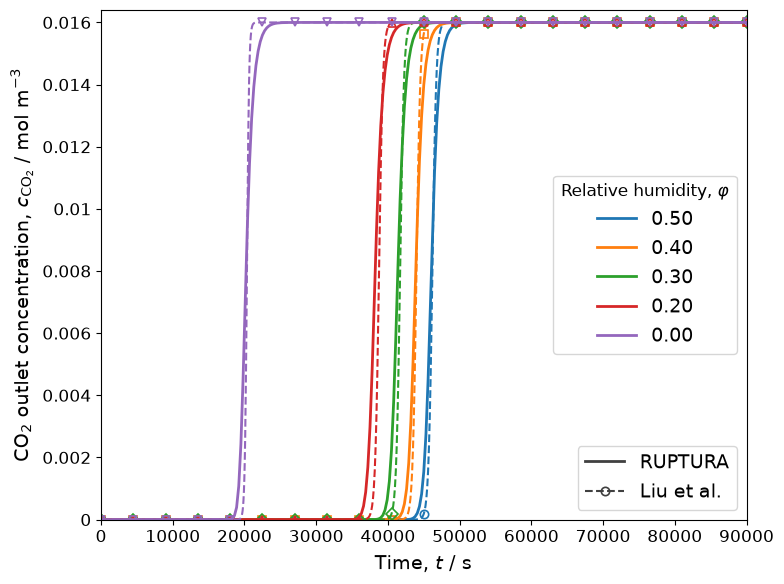

In [12]:
fig, ax = plt.subplots()
handles = []
for index, humidity in enumerate([0.50, 0.40, 0.30, 0.20, 0.0]):
    entry = case(figure=4, relative_humidity=humidity)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(
        data["time_s"], data["concentration_mol_m3"][:, -1], color=color, **RUPTURA_STYLE
    )
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))
    print(f"phi={humidity:.2f}  worst backward step {worst_backward_step(data["concentration_mol_m3"][:, -1]):+.2e}")

    reference_time, reference_concentration = reference(
        4, "time_s", "co2_concentration_mol_m3", relative_humidity=humidity
    )
    ax.plot(
        reference_time,
        reference_concentration,
        color=color,
        marker=REFERENCE_MARKERS[index],
        markevery=max(1, len(reference_time) // 20),
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"CO$_2$ outlet concentration, $c_\mathrm{CO_2}$ / mol m$^{-3}$")
ax.set_xlim(0.0, 90_000.0)
ax.set_ylim(0.0, 0.0164)
ax.xaxis.set_major_formatter(TICKS)
ax.yaxis.set_major_formatter(TICKS)
source_legend(
    ax,
    handles,
    condition_loc="center right",
    source_loc="lower right",
    title=r"Relative humidity, $\varphi$",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_4a.pdf", dpi=300)

### Figure 4b - H$_2$O outlet relative humidity

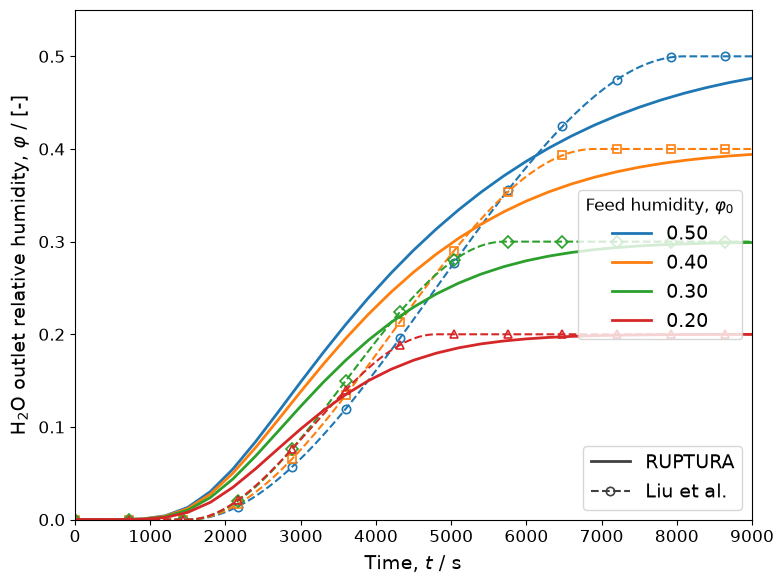

In [13]:
fig, ax = plt.subplots()
handles = []
for index, humidity in enumerate([0.50, 0.40, 0.30, 0.20]):
    entry = case(figure=4, relative_humidity=humidity)
    data = read_component(entry, "H2O")
    saturation_pressure = entry["water_saturation_pressure_pa"]
    color = f"C{index}"
    ax.plot(
        data["time_s"],
        data["partial_pressure_pa"][:, -1] / saturation_pressure,
        color=color,
        **RUPTURA_STYLE,
    )
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    reference_time, reference_humidity = reference(
        4, "time_s", "water_relative_humidity", relative_humidity=humidity
    )
    inside = reference_time <= 9_000.0
    ax.plot(
        reference_time[inside],
        reference_humidity[inside],
        color=color,
        marker=REFERENCE_MARKERS[index],
        markevery=max(1, int(inside.sum()) // 12),
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"H$_2$O outlet relative humidity, $\varphi$ / [-]")
ax.set_xlim(0.0, 9_000.0)
ax.set_ylim(0.0, 0.55)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax,
    handles,
    condition_loc="center right",
    source_loc="lower right",
    title=r"Feed humidity, $\varphi_0$",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_4b.pdf", dpi=300)

### Figure 4c - CO$_2$ loading

phi=0.50  worst backward step -1.11e-16
phi=0.40  worst backward step -1.11e-16


phi=0.30  worst backward step -1.11e-16
phi=0.20  worst backward step -5.55e-17


phi=0.00  worst backward step -1.11e-16


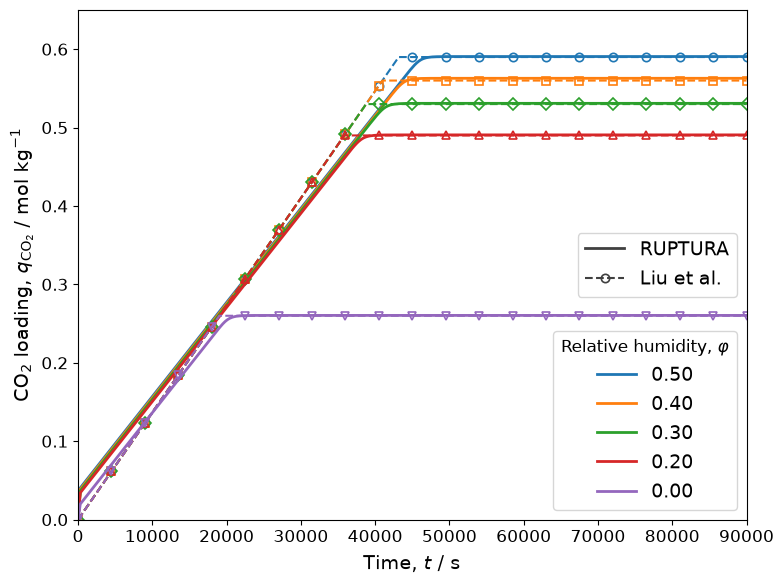

In [14]:
fig, ax = plt.subplots()
handles = []
for index, humidity in enumerate([0.50, 0.40, 0.30, 0.20, 0.0]):
    entry = case(figure=4, relative_humidity=humidity)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(
        data["time_s"], data["loading_mol_kg"].mean(axis=1), color=color, **RUPTURA_STYLE
    )
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))
    print(f"phi={humidity:.2f}  worst backward step {worst_backward_step(data["loading_mol_kg"].mean(axis=1)):+.2e}")

    reference_time, reference_loading = reference(
        4, "time_s", "co2_loading_mol_kg", relative_humidity=humidity
    )
    ax.plot(
        reference_time,
        reference_loading,
        color=color,
        marker=REFERENCE_MARKERS[index],
        markevery=max(1, len(reference_time) // 20),
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"CO$_2$ loading, $q_\mathrm{CO_2}$ / mol kg$^{-1}$")
ax.set_xlim(0.0, 90_000.0)
ax.set_ylim(0.0, 0.65)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax,
    handles,
    condition_loc="lower right",
    source_loc="center right",
    title=r"Relative humidity, $\varphi$",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_4c.pdf", dpi=300)

### Figure 4d - H$_2$O loading

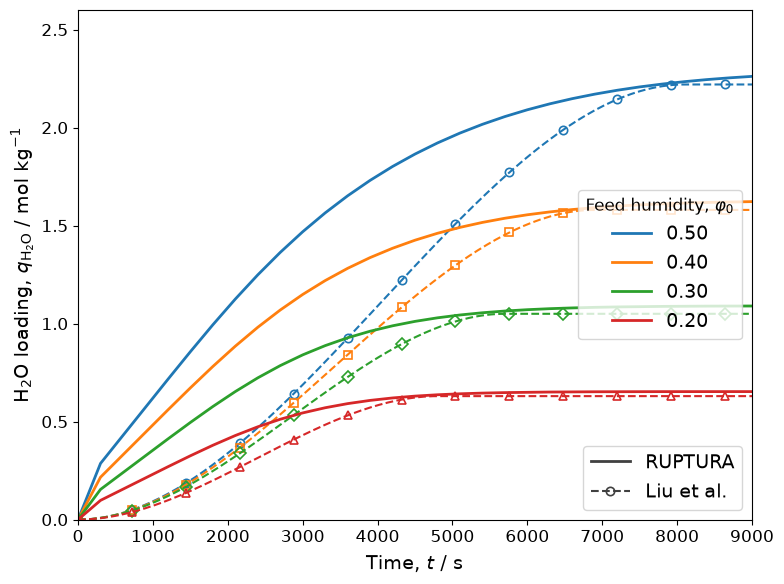

In [15]:
fig, ax = plt.subplots()
handles = []
for index, humidity in enumerate([0.50, 0.40, 0.30, 0.20]):
    entry = case(figure=4, relative_humidity=humidity)
    data = read_component(entry, "H2O")
    color = f"C{index}"
    ax.plot(
        data["time_s"], data["loading_mol_kg"].mean(axis=1), color=color, **RUPTURA_STYLE
    )
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    reference_time, reference_loading = reference(
        4, "time_s", "water_loading_mol_kg", relative_humidity=humidity
    )
    inside = reference_time <= 9_000.0
    ax.plot(
        reference_time[inside],
        reference_loading[inside],
        color=color,
        marker=REFERENCE_MARKERS[index],
        markevery=max(1, int(inside.sum()) // 12),
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"H$_2$O loading, $q_\mathrm{H_2O}$ / mol kg$^{-1}$")
ax.set_xlim(0.0, 9_000.0)
ax.set_ylim(0.0, 2.6)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax,
    handles,
    condition_loc="center right",
    source_loc="lower right",
    title=r"Feed humidity, $\varphi_0$",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_4d.pdf", dpi=300)

## Figure 5 - PEI-fiber equilibrium

The GAB water isotherm of the PEI/silica hollow-fiber sorbent and its temperature-dependent CO$_2$ Toth isotherms, including the empirical humid enhancement $\exp(1.11\,\varphi)$ of equation 8, which multiplies the whole loading. The 0.85 RH isotherm is RUPTURA's `Exponential-humidity-Toth` site at a fixed `RelativeHumidity` of 0.85.

### Figure 5a - GAB water isotherm at 308 K

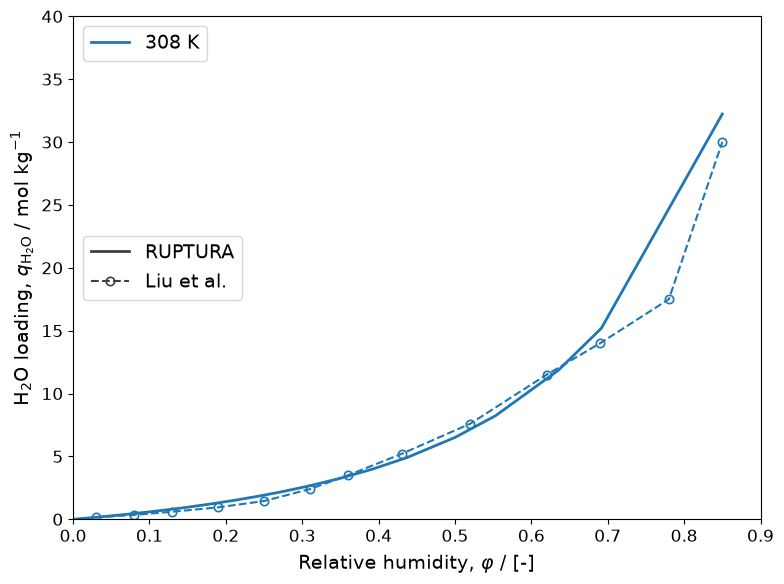

In [16]:
fig, ax = plt.subplots()
entry = case(figure=5, panel="a")
pressure, loading = sampled_isotherm(entry, "H2O")
humidity = pressure / entry["water_saturation_pressure_pa"]
ax.plot(humidity, loading, color="C0", **RUPTURA_STYLE)

reference_humidity, reference_loading = reference(
    5, "relative_humidity", "loading_mol_kg", dataset="water_isotherm"
)
ax.plot(reference_humidity, reference_loading, color="C0", marker="o", **REFERENCE_STYLE)

ax.set_xlabel(r"Relative humidity, $\varphi$ / [-]")
ax.set_ylabel(r"H$_2$O loading, $q_\mathrm{H_2O}$ / mol kg$^{-1}$")
ax.set_xlim(0.0, 0.9)
ax.set_ylim(0.0, 40.0)
source_legend(
    ax,
    [Line2D([], [], color="C0", label=entry["legend"], **RUPTURA_STYLE)],
    condition_loc="upper left",
    source_loc="center left",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_5a.pdf", dpi=300)

### Figure 5b - CO$_2$ isotherms

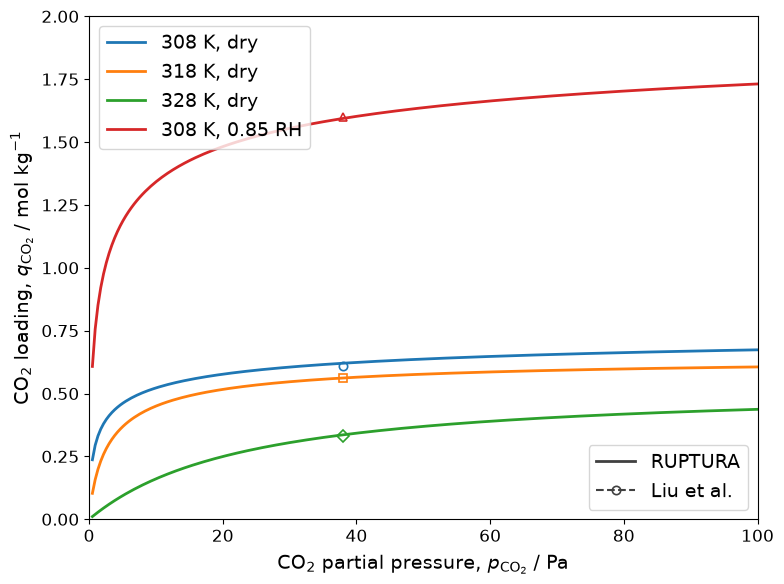

In [17]:
fig, ax = plt.subplots()
handles = []
for index, (temperature, humidity) in enumerate(
    [(308.0, 0.0), (318.0, 0.0), (328.0, 0.0), (308.0, 0.85)]
):
    entry = case(figure=5, panel="b", temperature_K=temperature, relative_humidity=humidity)
    pressure, loading = read_isotherm(entry, "CO2")
    color = f"C{index}"
    ax.plot(pressure, loading, color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    marker_pressure, marker_loading = reference(
        5,
        "pressure_pa",
        "loading_mol_kg",
        dataset="co2_isotherm",
        temperature_K=temperature,
        relative_humidity=humidity,
    )
    ax.plot(
        marker_pressure,
        marker_loading,
        color=color,
        marker=REFERENCE_MARKERS[index],
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"CO$_2$ partial pressure, $p_\mathrm{CO_2}$ / Pa")
ax.set_ylabel(r"CO$_2$ loading, $q_\mathrm{CO_2}$ / mol kg$^{-1}$")
ax.set_xlim(0.0, 100.0)
ax.set_ylim(0.0, 2.0)
source_legend(ax, handles, condition_loc="upper left", source_loc="lower right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_5b.pdf", dpi=300)

## Figure 6 - dry direct air capture

Dry 380 ppm CO$_2$ breakthrough through the fiber module at 308, 318 and 328 K, each at standard volumetric flows of $6.67\times10^{-7}$, $1.00\times10^{-6}$ and $1.50\times10^{-6}$ m$^3$ s$^{-1}$ referenced to 273.15 K and 100000 Pa. The effective bulk density of 80 kg m$^{-3}$ is inferred from the printed time axes; the article does not report the loaded module mass.

### Figure 6a - 308 K

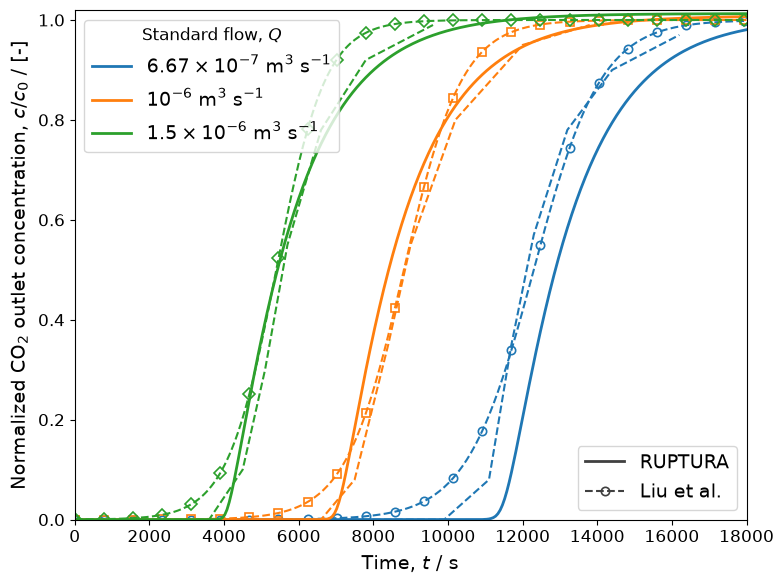

In [18]:
fig, ax = plt.subplots()
handles = []
for index, flow in enumerate([6.6666666667e-7, 1.0e-6, 1.5e-6]):
    entry = case(figure=6, temperature_K=308.0, standard_flow_m3_s=flow)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    for dataset, every in (("paper_curve", 22), ("paper_marker", 1)):
        reference_time, reference_outlet = reference(
            6,
            "time_s",
            "outlet_fraction",
            dataset=dataset,
            temperature_K=308.0,
            standard_flow_m3_s=flow,
        )
        ax.plot(
            reference_time,
            reference_outlet,
            color=color,
            marker=REFERENCE_MARKERS[index],
            markevery=max(1, len(reference_time) // every),
            **REFERENCE_STYLE,
        )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(0.0, 18_000.0)
ax.set_ylim(0.0, 1.02)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax, handles, condition_loc="upper left", source_loc="lower right", title=r"Standard flow, $Q$"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_6a.pdf", dpi=300)

### Figure 6b - 318 K

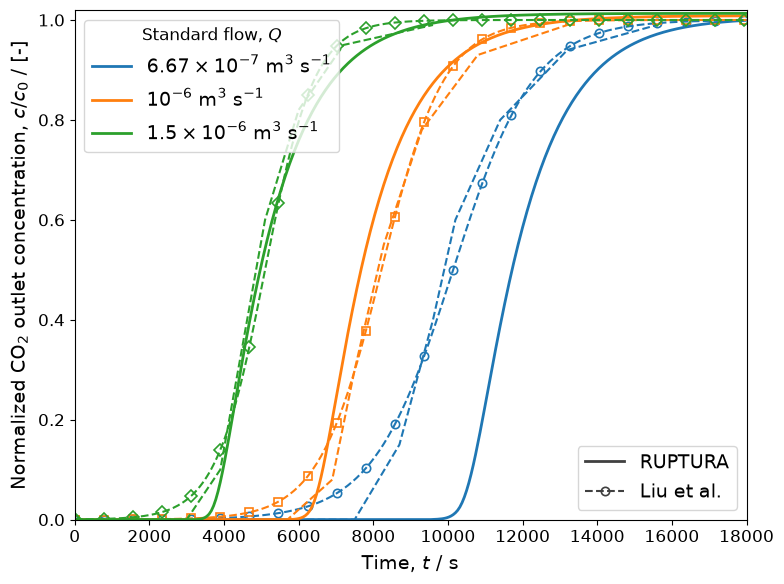

In [19]:
fig, ax = plt.subplots()
handles = []
for index, flow in enumerate([6.6666666667e-7, 1.0e-6, 1.5e-6]):
    entry = case(figure=6, temperature_K=318.0, standard_flow_m3_s=flow)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    for dataset, every in (("paper_curve", 22), ("paper_marker", 1)):
        reference_time, reference_outlet = reference(
            6,
            "time_s",
            "outlet_fraction",
            dataset=dataset,
            temperature_K=318.0,
            standard_flow_m3_s=flow,
        )
        ax.plot(
            reference_time,
            reference_outlet,
            color=color,
            marker=REFERENCE_MARKERS[index],
            markevery=max(1, len(reference_time) // every),
            **REFERENCE_STYLE,
        )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(0.0, 18_000.0)
ax.set_ylim(0.0, 1.02)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax, handles, condition_loc="upper left", source_loc="lower right", title=r"Standard flow, $Q$"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_6b.pdf", dpi=300)

### Figure 6c - 328 K

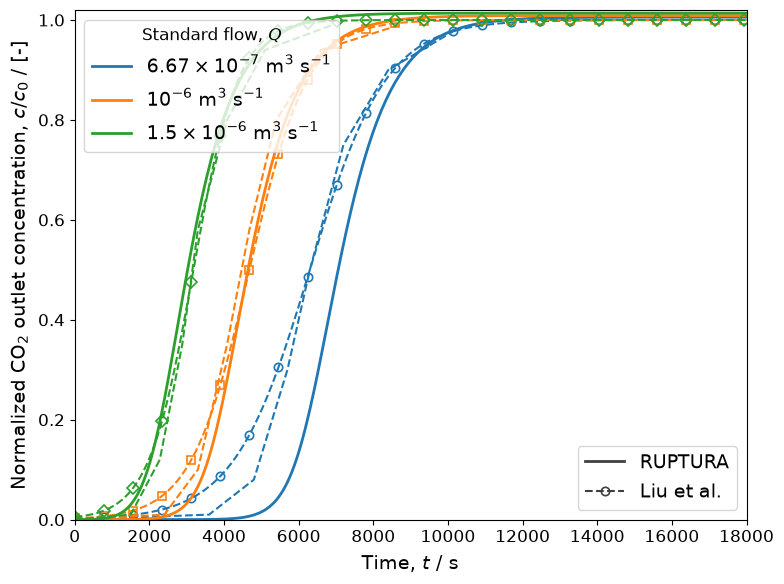

In [20]:
fig, ax = plt.subplots()
handles = []
for index, flow in enumerate([6.6666666667e-7, 1.0e-6, 1.5e-6]):
    entry = case(figure=6, temperature_K=328.0, standard_flow_m3_s=flow)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    for dataset, every in (("paper_curve", 22), ("paper_marker", 1)):
        reference_time, reference_outlet = reference(
            6,
            "time_s",
            "outlet_fraction",
            dataset=dataset,
            temperature_K=328.0,
            standard_flow_m3_s=flow,
        )
        ax.plot(
            reference_time,
            reference_outlet,
            color=color,
            marker=REFERENCE_MARKERS[index],
            markevery=max(1, len(reference_time) // every),
            **REFERENCE_STYLE,
        )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(0.0, 18_000.0)
ax.set_ylim(0.0, 1.02)
ax.xaxis.set_major_formatter(TICKS)
source_legend(
    ax, handles, condition_loc="upper left", source_loc="lower right", title=r"Standard flow, $Q$"
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_6c.pdf", dpi=300)

## Figure 7 - dry versus humid direct air capture

Dry and 0.85 relative-humidity CO$_2$ breakthrough at 308 K and a standard flow of $3.33\times10^{-6}$ m$^3$ s$^{-1}$. The humid run carries a GAB water component (`"Water": true`) alongside the CO$_2$ `Exponential-humidity-Toth` site, whose saturation loading is enhanced by $\exp(1.11\,\varphi)$ at the local humidity, reaching $\exp(1.11 \times 0.85)$ behind the water front. This campaign used a separate physical module, so its effective bulk density of 160.9 kg m$^{-3}$ differs from Figure 6.

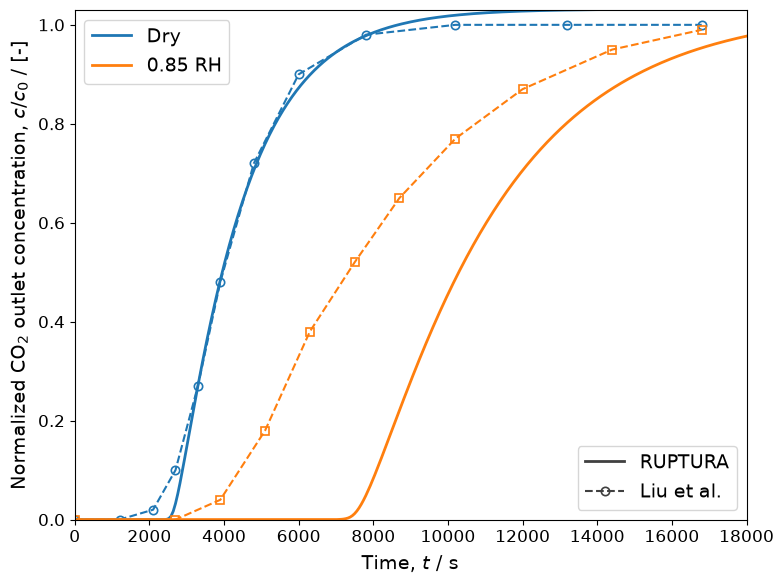

In [21]:
fig, ax = plt.subplots()
handles = []
for index, condition in enumerate(["dry", "humid_85pct"]):
    entry = case(figure=7, condition=condition)
    data = read_component(entry, "CO2")
    color = f"C{index}"
    ax.plot(data["time_s"], data["normalized_pressure"][:, -1], color=color, **RUPTURA_STYLE)
    handles.append(Line2D([], [], color=color, label=entry["legend"], **RUPTURA_STYLE))

    reference_time, reference_outlet = reference(
        7, "time_s", "outlet_fraction", condition=condition
    )
    ax.plot(
        reference_time,
        reference_outlet,
        color=color,
        marker=REFERENCE_MARKERS[index],
        **REFERENCE_STYLE,
    )

ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Normalized CO$_2$ outlet concentration, $c/c_0$ / [-]")
ax.set_xlim(0.0, 18_000.0)
ax.set_ylim(0.0, 1.03)
ax.xaxis.set_major_formatter(TICKS)
source_legend(ax, handles, condition_loc="upper left", source_loc="lower right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure_7.pdf", dpi=300)